# 5. Оценка на test, экономика и сегменты

Всё про test посчитано одним запуском `python -m src.evaluate_test` по плану, замороженному до первого обращения
к test (`docs/plan.md`, «Заморозка перед test»). Этот ноутбук только читает `artifacts/test_results.json`.
Сегменты в конце - разведка на valid, test для них не используется. После запуска на test исправлены только
ошибки отображения в этом ноутбуке, цифры не менялись.

In [1]:
import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config, models, plots, stats

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plots.setup()
res = json.loads((models.ARTIFACTS / "test_results.json").read_text())
FINAL = "class_transformation"
ORDER = ["class_transformation", "t_learner", "response", "inverse_response"]
ks = res["ks"]
shares = np.array(res["shares"])
r_grid = np.array(res["r_grid"])
ate = res["ate"]
print(f"test: {res['n']} клиентов, treatment {res['n_treatment']}, control {res['n_control']}")
print(f"ATE_test = {ate * 100:.2f} п.п. ({res['ate_ci'][0] * 100:.2f} ... {res['ate_ci'][1] * 100:.2f}), "
      f"бутстреп B = {res['n_boot']}, seed {res['boot_seed']}")
_, y_v, t_v = models.load("valid")
print(f"ATE_valid = {(y_v[t_v == 1].mean() - y_v[t_v == 0].mean()) * 100:.4f} п.п., ATE_test = {ate * 100:.4f} п.п.")

test: 40008 клиентов, treatment 19996, control 20012
ATE_test = 3.32 п.п. (2.35 ... 4.30), бутстреп B = 1000, seed 42


ATE_valid = 3.3239 п.п., ATE_test = 3.3239 п.п.


ATE_test в точности равен ATE_valid. Это следствие разбиения, а не ошибка: стратификация по treatment x target при
одинаковых размерах valid и test даёт одинаковые числа клиентов в каждой из четырёх ячеек (19 996 / 20 012
клиентов и 12 728 / 12 073 покупателей). Поэтому средний эффект на test не несёт независимой информации, а его интервал
отражает только выборочный шум.

## Метрики на test

Финальная модель - трансформация классов seed 42, остальные строки - бейзлайны. Интервалы - парный бутстреп
внутри групп, «неопределённость оценки на test»; у случайной рассылки интервал Qini - 95% случайных перестановок.

In [2]:
def fmt(v, c, scale=1, digits=3):
    return f"{v * scale:.{digits}f} ({c[0] * scale:.{digits}f} ... {c[1] * scale:.{digits}f})"


rows = []
for m in ORDER:
    r = res["models"][m]
    row = {"модель": plots.MODEL_NAMES[m], "Qini": fmt(r["metrics"]["qini"], r["metrics_ci"]["qini"])}
    for k in ks:
        c = f"uplift@{k:.0%}"
        row[f"доп. на 1000 @{k:.0%}"] = fmt(r["metrics"][c], r["metrics_ci"][c], 1000, 0)
        n_t, n_c = r["counts"][f"{k:.0%}"]
        row[f"n_t/n_c @{k:.0%}"] = f"{n_t}/{n_c}"
    rows.append(row)
q = res["random"]["metrics_ci"]["qini"]
random_row = {"модель": "случайная рассылка", "Qini": f"0 ({q[0]:.3f} ... {q[1]:.3f})"}
for k in ks:
    random_row[f"доп. на 1000 @{k:.0%}"] = fmt(ate, res["ate_ci"], 1000, 0)
    random_row[f"n_t/n_c @{k:.0%}"] = "-"
rows.append(random_row)
pd.DataFrame(rows).set_index("модель")

,Qini,доп. на 1000 @10%,n_t/n_c @10%,доп. на 1000 @20%,n_t/n_c @20%,доп. на 1000 @30%,n_t/n_c @30%
модель,,,,,,,
трансформация классов,0.015 (0.009 ... 0.022),112 (80 ... 142),1987/2013,88 (65 ... 109),3982/4019,62 (45 ... 79),5968/6034
T-learner,0.012 (0.005 ... 0.019),102 (69 ... 129),1974/2026,73 (51 ... 94),3975/4026,53 (34 ... 71),5967/6035
модель отклика,-0.006 (-0.012 ... -0.001),8 (-5 ... 21),1973/2027,14 (3 ... 25),3982/4019,11 (1 ... 23),5972/6030
обратный отклик,0.008 (0.002 ... 0.014),28 (2 ... 57),2000/2000,32 (14 ... 52),4021/3980,38 (22 ... 55),5997/6005
случайная рассылка,0 (-0.006 ... 0.006),33 (24 ... 43),-,33 (24 ... 43),-,33 (24 ... 43),-


In [3]:
rows = []
for name, d in res["differences"].items():
    a, b = name.split(" - ")
    row = {"разность": f"трансформация классов - {plots.MODEL_NAMES.get(b, 'случайная')}"}
    row["Qini"] = fmt(d["qini"]["estimate"], d["qini"]["ci"])
    for k in ks:
        c = f"uplift@{k:.0%}"
        row[f"доп. на 1000 @{k:.0%}"] = fmt(d[c]["estimate"], d[c]["ci"], 1000, 0)
    rows.append(row)
pd.DataFrame(rows).set_index("разность")

,Qini,доп. на 1000 @10%,доп. на 1000 @20%,доп. на 1000 @30%
разность,,,,
трансформация классов - T-learner,0.003 (-0.003 ... 0.009),10 (-20 ... 44),15 (-6 ... 35),9 (-6 ... 25)
трансформация классов - модель отклика,0.022 (0.012 ... 0.031),104 (68 ... 137),74 (47 ... 96),51 (30 ... 68)
трансформация классов - обратный отклик,0.008 (-0.001 ... 0.016),84 (42 ... 122),56 (29 ... 79),24 (1 ... 43)
трансформация классов - случайная,0.015 (0.009 ... 0.022),78 (49 ... 109),55 (33 ... 73),29 (15 ... 44)


Для разности со случайной рассылкой Qini сравнивается с нулём (интервал - бутстреп Qini финальной модели),
uplift@k - с ATE_test на той же бутстреп-выборке.

- Финальная модель на test: Qini 0,015 (0,009 ... 0,022), при рассылке топ-10% - 112 дополнительных покупателей
  на 1 000 сообщений (80 ... 142), топ-20% - 88, топ-30% - 62. Случайная рассылка - 33 (24 ... 43).
- Против случайной рассылки: +78 (+49 ... +109) в топ-10%, +55 в топ-20%, +29 в топ-30%, все интервалы выше нуля.
- Против модели отклика: Qini +0,022 (0,012 ... 0,031), +104 (+68 ... +137) в топ-10%. Модель отклика и на test
  хуже случайной: Qini -0,006 (-0,012 ... -0,001).
- Против обратного отклика: по Qini +0,008 (-0,001 ... 0,016) - не значимо. По uplift@k значимо: +84 (+42 ... +122)
  в топ-10%, +56 (+29 ... +79) в топ-20%, +24 (+1 ... +43) в топ-30%.
- Против T-learner: Qini +0,003 (-0,003 ... 0,009), +10 (-20 ... +44) в топ-10% - разницы нет, как и на valid.
- Результат на test не хуже valid: у финальной модели на valid было Qini 0,013 и 96 в топ-10%, на test - 0,015 и 112.
- Обратный отклик в топ-10% на test - 28 (2 ... 57), ниже случайной рассылки (33), но в пределах шума: интервалы
  перекрываются. На valid он давал 45, а нижние децили модели отклика - 4,5-5,6 п.п. эффекта.

Почему против обратного отклика Qini не значим, а uplift@k значим. Qini интегрирует всю кривую, а все кривые
сходятся в одной точке «слать всем» (100% базы, ATE). Обратный отклик догоняет модель ко второй половине базы,
и площадь между кривыми набирается только в начале. uplift@10/20/30 смотрит как раз на начало списка. Для решения
о бюджете ни та, ни другая метрика не ответ: смотрю прибыль при заданном r (ниже).

## Qini-кривые на test

Qini-кривая в абсолютных единицах: дополнительные покупатели на 100 000 клиентов базы при рассылке первым k% по скору,
100 000 x k x uplift@k. Полосы - бутстреп-интервалы финальной модели и 95% случайных перестановок.

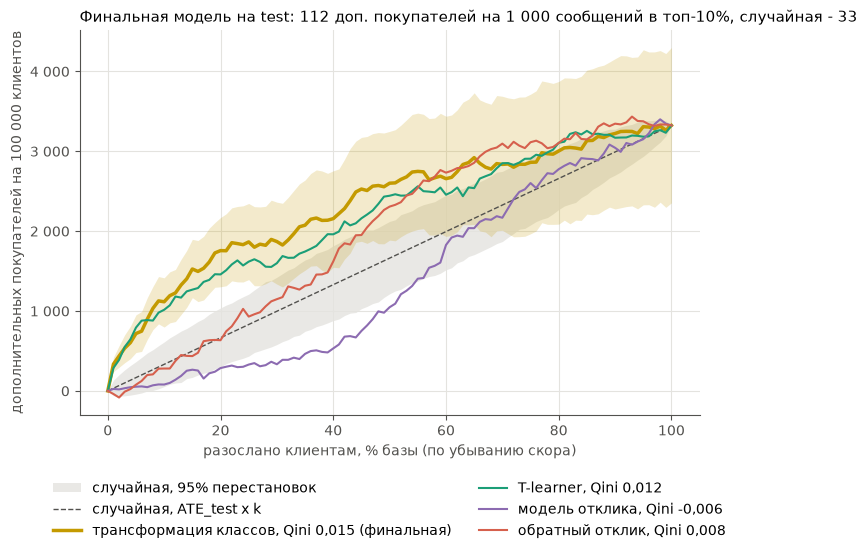

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
band = np.array(res["random"]["gain_band"]) * 1e5
ax.fill_between(shares * 100, band[0], band[1], color=plots.GRID, alpha=0.8, lw=0, label="случайная, 95% перестановок")
ax.plot([0, 100], [0, ate * 1e5], color=plots.INK, ls="--", lw=1, label="случайная, ATE_test x k")
for m in ORDER:
    r = res["models"][m]
    g = np.array(r["gain"]) * 1e5
    lw = 2.5 if m == FINAL else 1.5
    label = f"{plots.MODEL_NAMES[m]}, Qini {r['metrics']['qini']:.3f}".replace(".", ",")
    ax.plot(shares * 100, g, color=plots.MODEL_COLORS[m], lw=lw, label=label + (" (финальная)" if m == FINAL else ""))
    if m == FINAL:
        lo, hi = np.array(r["gain_ci"]) * 1e5
        ax.fill_between(shares * 100, lo, hi, color=plots.MODEL_COLORS[m], alpha=0.2, lw=0)
ax.set_xlabel("разослано клиентам, % базы (по убыванию скора)")
ax.set_ylabel("дополнительных покупателей на 100 000 клиентов")
plots.thousands(ax.yaxis)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2)
ax.set_title('Финальная модель на test: 112 доп. покупателей на 1 000 сообщений в топ-10%, случайная - 33')
plots.save(fig, "qini_test.png")
plt.show()

Кривая финальной модели выше коридора случайных перестановок примерно до 60% базы. Обратный отклик до ~35%
идёт внутри коридора и догоняет uplift-модели только к половине базы: его эффект размазан, а uplift-модели
собирают его в начале списка. Модель отклика ниже коридора примерно с 10 до 70%.

## Экономика

C - стоимость сообщения, V - ценность дополнительного покупателя; обе неизвестны. Прибыль в единицах V на 100 000
клиентов: 100 000 x (gain(k) - r x k), где r = C / V. Сетка r от 0 до 0,30 - допущение. Долю k для каждого r выбираю
на valid, прибыль при ней - на test. Рассылка всем безубыточна при r = ATE.

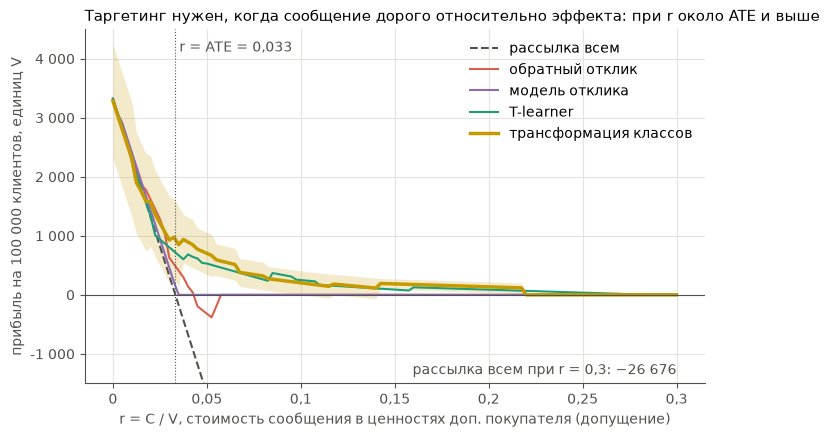

In [5]:
econ = res["economics"]
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.plot(r_grid, econ["send_all"]["profit"], color=plots.INK, lw=1.5, ls="--", label="рассылка всем")
for m in ["inverse_response", "response", "t_learner", FINAL]:
    lw = 2.5 if m == FINAL else 1.5
    ax.plot(r_grid, econ[m]["profit"], color=plots.MODEL_COLORS[m], lw=lw, label=plots.MODEL_NAMES[m])
lo, hi = econ[FINAL]["profit_ci"]
ax.fill_between(r_grid, lo, hi, color=plots.MODEL_COLORS[FINAL], alpha=0.2, lw=0)
ax.axhline(0, color=plots.INK, lw=0.8)
ax.axvline(ate, color=plots.INK, lw=0.8, ls=":")
ax.set_ylim(-1500, 4500)
ax.text(ate, 4300, f" r = ATE = {ate:.3f}".replace(".", ","), color=plots.INK, va="top")
loss = f"{econ['send_all']['profit'][-1]:,.0f}".replace(",", " ").replace("-", "−")
ax.text(0.30, -1400, f"рассылка всем при r = 0,3: {loss}",
        color=plots.INK, ha="right", va="bottom")
ax.set_xlabel("r = C / V, стоимость сообщения в ценностях доп. покупателя (допущение)")
ax.set_ylabel("прибыль на 100 000 клиентов, единиц V")
plots.decimal_comma(ax.xaxis)
plots.thousands(ax.yaxis)
ax.legend(loc="upper right")
ax.set_title('Таргетинг нужен, когда сообщение дорого относительно эффекта: при r около ATE и выше')
plots.save(fig, "economics_test.png")
plt.show()

Три бейзлайна для решения о бюджете: рассылка всем, обратный отклик с долей, выбранной на valid, и «не писать
никому» (прибыль 0). Разность с «никому» - это сама прибыль модели, её интервал - бутстреп прибыли. Бутстреп-выборки
не сохранялись, но все интервалы ниже посчитаны в том же единственном запуске и лежат в `test_results.json`:
пересчитывать ничего не пришлось.

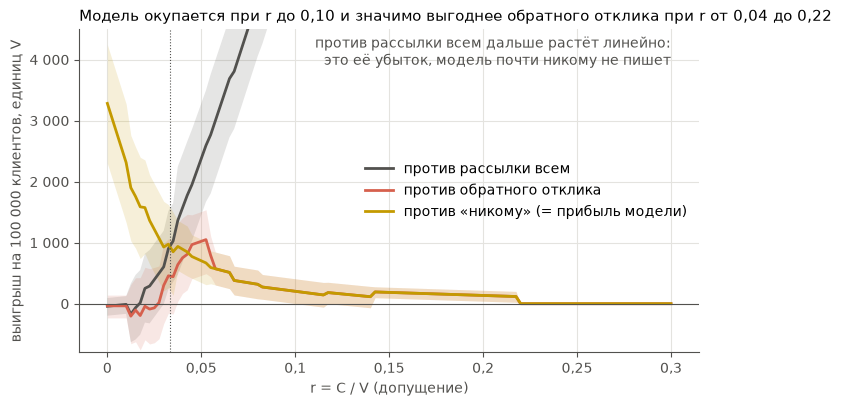

In [6]:
econ["gain_vs_nobody"] = {"estimate": econ[FINAL]["profit"], "ci": econ[FINAL]["profit_ci"]}
fig, ax = plt.subplots(figsize=(8, 4.2))
for name, label, color in [("gain_vs_send_all", "против рассылки всем", plots.INK),
                           ("gain_vs_inverse_response", "против обратного отклика", plots.MODEL_COLORS["inverse_response"]),
                           ("gain_vs_nobody", "против «никому» (= прибыль модели)", plots.MODEL_COLORS[FINAL])]:
    g = econ[name]
    ax.plot(r_grid, g["estimate"], color=color, lw=2, label=label)
    ax.fill_between(r_grid, g["ci"][0], g["ci"][1], color=color, alpha=0.15, lw=0)
ax.axhline(0, color=plots.INK, lw=0.8)
ax.axvline(ate, color=plots.INK, lw=0.8, ls=":")
ax.set_ylim(-800, 4500)
ax.text(0.30, 4400, "против рассылки всем дальше растёт линейно:\nэто её убыток, модель почти никому не пишет",
        color=plots.INK, ha="right", va="top")
ax.set_xlabel("r = C / V (допущение)")
ax.set_ylabel("выигрыш на 100 000 клиентов, единиц V")
plots.decimal_comma(ax.xaxis)
plots.thousands(ax.yaxis)
ax.legend(loc="center right")
ax.set_title('Модель окупается при r до 0,10 и значимо выгоднее обратного отклика при r от 0,04 до 0,22')
plots.save(fig, "gain_vs_r_test.png")
plt.show()

In [7]:
def interval(est, lo, hi, i):
    return f"{est[i]:+.0f} ({lo[i]:+.0f} ... {hi[i]:+.0f})"


rows = []
for i, r in enumerate(r_grid):
    row = {"r": r, "k": econ[FINAL]["share_chosen_on_valid"][i]}
    p = econ[FINAL]
    row["прибыль модели"] = interval(p["profit"], *p["profit_ci"], i)
    for name, label in [("gain_vs_send_all", "против всем"), ("gain_vs_inverse_response", "против обратного отклика"),
                        ("gain_vs_nobody", "против никому")]:
        g = econ[name]
        row[label] = interval(g["estimate"], *g["ci"], i)
    rows.append(row)
by_r = pd.DataFrame(rows).set_index("r")
with pd.option_context("display.max_rows", 200):
    display(by_r)

,k,прибыль модели,против всем,против обратного отклика,против никому
r,,,,,
0.0000,0.97,+3282 (+2300 ... +4244),-42 (-197 ... +93),-35 (-233 ... +141),+3282 (+2300 ... +4244)
0.0025,0.97,+3040 (+2057 ... +4002),-34 (-189 ... +101),-35 (-233 ... +141),+3040 (+2057 ... +4002)
0.0050,0.97,+2797 (+1815 ... +3759),-27 (-182 ... +108),-35 (-233 ... +141),+2797 (+1815 ... +3759)
0.0075,0.97,+2555 (+1572 ... +3517),-19 (-174 ... +116),-35 (-233 ... +141),+2555 (+1572 ... +3517)
0.0100,0.97,+2312 (+1330 ... +3274),-12 (-167 ... +123),-35 (-233 ... +141),+2312 (+1330 ... +3274)
0.0125,0.72,+1900 (+1029 ... +2757),-174 (-632 ... +330),-204 (-657 ... +317),+1900 (+1029 ... +2757)
0.0150,0.68,+1757 (+910 ... +2569),-67 (-588 ... +471),-105 (-624 ... +424),+1757 (+910 ... +2569)
0.0175,0.68,+1587 (+740 ... +2399),+13 (-508 ... +551),-194 (-757 ... +427),+1587 (+740 ... +2399)
0.0200,0.63,+1575 (+821 ... +2355),+251 (-310 ... +818),-42 (-591 ... +596),+1575 (+821 ... +2355)


In [8]:
lo = np.array(econ[FINAL]["profit_ci"][0])
k = np.array(econ[FINAL]["share_chosen_on_valid"])
first_bad = int(np.argmax(lo <= 0))
later = np.arange(len(r_grid)) >= first_bad
print(f"интервал прибыли выше нуля непрерывно при r от 0 до {r_grid[first_bad - 1]:.4f}")
noise = later & (lo > 0)
n_send = sorted({int(res["n"] * x) for x in k[noise]})
print(f"дальше выше нуля - {int(noise.sum())} отдельных r от {r_grid[noise].min():.4f} до {r_grid[noise].max():.4f}, "
      f"доля рассылки в них: {sorted(float(x) for x in set(k[noise]))}, это {n_send} клиентов test на обе группы")

интервал прибыли выше нуля непрерывно при r от 0 до 0.1000
дальше выше нуля - 32 отдельных r от 0.1175 до 0.2175, доля рассылки в них: [0.01, 0.03], это [400, 1200] клиентов test на обе группы


- Граница для рассылки всем: она окупается при r < ATE = 0,0332. Модель окупается шире: результат - непрерывный
  диапазон r от 0 до 0,10, где интервал её прибыли выше нуля.
- Отдельные точки выше 0,10, где нижняя граница интервала тоже чуть выше нуля, считаю шумом: это 121
  коррелированное сравнение по сетке r, а модель там пишет 1-3% базы - на test это от 200 до 600 клиентов
  на группу.
- При r до 0,01 модель выбирает 97% базы и от рассылки всем не отличается: -42 (-197 ... +93) при r = 0.
  От 0,0125 до 0,03 она пишет 58-72% базы, но выигрыш над рассылкой всем ещё не значим.
- При r около ATE (0,0325) рассылка всем выходит в ноль (+74), модель пишет половине базы и получает 975:
  выигрыш +901 (+232 ... +1 519), с этого r он значим. Против обратного отклика здесь +457 (-154 ... +1 065).
- При r = 0,05 модель пишет 14% базы и получает 703, обратный отклик с долей, выбранной на valid (25%), на test
  уходит в минус (-320): выигрыш +1 023 (+464 ... +1 511). Выигрыш над обратным откликом значим при r
  от 0,0375 до 0,2175 и максимален около r = 0,05 - примерно 1 050 V на 100 000 клиентов.

Вывод: если сообщение дешевле среднего эффекта, можно писать всем, модель значимо не добавляет. Если дороже,
рассылка всем убыточна, а таргетинг по модели окупается примерно до r = 0,10.

## Четыре типа клиентов на уровне базы

Тип клиента - пара его исходов с сообщением и без: «купят и так» (1, 1), «переубеждаемые» (1, 0), «не купят
в любом случае» (0, 0), «реагируют отрицательно» (0, 1). У одного клиента видно только один исход, поэтому типы
не наблюдаются, а поклиентно их не оценить. Но доли типов во всей базе связаны с долями покупателей p_t и p_c,
которые эксперимент оценивает без смещения. Считаю на всех 200 039 клиентах, как средний эффект на этапе 2:
это описание эксперимента, модели здесь не выбираются.

- Без допущений: p_t - p_c = переубеждаемые - реагируют отрицательно. Отсюда доля переубеждаемых лежит
  в [p_t - p_c, min(p_t, 1 - p_c)], доля реагирующих отрицательно - в [0, min(p_c, 1 - p_t)].
- Допущение «отрицательной реакции нет» (монотонность): тогда доли точные - купят и так = p_c,
  переубеждаемые = p_t - p_c, не купят в любом случае = 1 - p_t. Проверить это допущение по данным нельзя.

In [9]:
from src import db

con = db.connect()
g = db.run(con, "experiment.sql", "target_by_group").set_index("treatment_flg")
p_t, t_lo, t_hi = stats.prop_ci(g.n_buyers[1], g.n_clients[1])
p_c, c_lo, c_hi = stats.prop_ci(g.n_buyers[0], g.n_clients[0])
d, d_lo, d_hi = stats.diff_props_ci(g.n_buyers[1], g.n_clients[1], g.n_buyers[0], g.n_clients[0])
print(f"p_t = {p_t:.4f}, p_c = {p_c:.4f}, p_t - p_c = {d:.4f} ({d_lo:.4f} ... {d_hi:.4f})")
types = pd.DataFrame({
    "без допущений": {
        "купят и так": f"от {max(0, p_t + p_c - 1):.3f} до {min(p_t, p_c):.3f}",
        "переубеждаемые": f"от {d:.3f} до {min(p_t, 1 - p_c):.3f}",
        "не купят в любом случае": f"от {max(0, (1 - p_t) - p_c):.3f} до {min(1 - p_t, 1 - p_c):.3f}",
        "реагируют отрицательно": f"от 0 до {min(p_c, 1 - p_t):.3f}",
    },
    "допущение: отрицательной реакции нет": {
        "купят и так": f"{p_c:.3f} ({c_lo:.3f} ... {c_hi:.3f})",
        "переубеждаемые": f"{d:.3f} ({d_lo:.3f} ... {d_hi:.3f})",
        "не купят в любом случае": f"{1 - p_t:.3f} ({1 - t_hi:.3f} ... {1 - t_lo:.3f})",
        "реагируют отрицательно": "0 (допущение)",
    },
})
types

p_t = 0.6365, p_c = 0.6033, p_t - p_c = 0.0332 (0.0290 ... 0.0375)


,без допущений,допущение: отрицательной реакции нет
купят и так,от 0.240 до 0.603,0.603 (0.600 ... 0.606)
переубеждаемые,от 0.033 до 0.397,0.033 (0.029 ... 0.037)
не купят в любом случае,от 0.000 до 0.363,0.363 (0.361 ... 0.366)
реагируют отрицательно,от 0 до 0.363,0 (допущение)


Без допущений доля переубеждаемых в базе - от 3,3% до 39,7%: эксперимент не отличает 3% переубеждаемых без
отрицательной реакции от, например, 20% переубеждаемых и 17% реагирующих отрицательно. При допущении, что
отрицательной реакции нет: 60,3% купят и так, 3,3% переубеждаемых, 36,3% не купят в любом случае. Тогда 96,7%
сообщений при рассылке всем уходят клиентам, решение которых оно не меняет.

## Сегменты на valid (разведка)

Описание клиентов, которых выбирают модели: топ-10% по финальной модели, топ-10% по модели отклика и все клиенты
valid. Новых выборов здесь нет: модели и пороги те же. Это описание, а не объяснение, почему модель их выбрала.

In [10]:
X_valid, y_v, t_v = models.load("valid")
vs = pd.read_parquet(models.ARTIFACTS / "valid_scores.parquet").query(f"seed == {config.SEED}")
vs = vs.pivot(index="client_id", columns="model", values="score").loc[X_valid.index]


def top_mask(score, share=0.1):
    mask = np.zeros(len(score), dtype=bool)
    mask[np.argsort(score, kind="mergesort")[::-1][: int(len(score) * share)]] = True
    return mask


groups = {
    "топ-10% трансформации классов": top_mask(vs[FINAL].to_numpy()),
    "топ-10% модели отклика": top_mask(vs["response"].to_numpy()),
    "все клиенты valid": np.ones(len(X_valid), dtype=bool),
}
rows = {}
for name, mask in groups.items():
    g = X_valid[mask]
    yy, tt = y_v[mask], t_v[mask]
    d, lo, hi = stats.diff_props_ci(yy[tt == 1].sum(), (tt == 1).sum(), yy[tt == 0].sum(), (tt == 0).sum())
    rows[name] = {
        "клиентов": int(mask.sum()),
        "дней с последней покупки, медиана": g.days_since_last.median(),
        "чеков за историю, медиана": g.n_trn_all.median(),
        "сумма за историю, руб., медиана": g.sum_all.median(),
        "давность карты, дней, медиана": g.card_age_days.median(),
        "доля чеков со списанием, среднее": g.share_spend_all.mean(),
        "возраст, медиана": g.age.median(),
        "пол F": (g.gender == "F").mean(),
        "пол M": (g.gender == "M").mean(),
        "пол U": (g.gender == "U").mean(),
        "купили, treatment": yy[tt == 1].mean(),
        "купили, control": yy[tt == 0].mean(),
        "uplift, п.п.": f"{d * 100:.1f} ({lo * 100:.1f} ... {hi * 100:.1f})",
    }
pd.DataFrame(rows).round(3)

,топ-10% трансформации классов,топ-10% модели отклика,все клиенты valid
клиентов,4000,4000,40008
"дней с последней покупки, медиана",5.0,0.0,4.0
"чеков за историю, медиана",10.0,51.0,15.0
"сумма за историю, руб., медиана",2834.0,14985.76,6097.025
"давность карты, дней, медиана",273.0,554.0,487.0
"доля чеков со списанием, среднее",0.148317,0.047998,0.071116
"возраст, медиана",58.0,48.0,45.0
пол F,0.39825,0.42725,0.369176
пол M,0.143,0.1755,0.167591
пол U,0.45875,0.39725,0.463232


Описание клиентов в топ-10% финальной модели: медиана 10 чеков против 15 у всех клиентов valid, сумма 2 834 руб.
против 6 097, давность карты 273 дня против 487, медиана возраста 58 лет против 45, доля чеков со списанием баллов
14,8% против 7,1%. Наблюдаемый uplift в этой группе 9,6 п.п. (6,5 ... 12,6), в control покупает 51%.
Топ-10% модели отклика: медиана давности последней покупки 0 дней, 51 чек, 15 тысяч руб., в control покупает 95%,
uplift 1,0 п.п. (-0,3 ... +2,3).

Простой понятный сегмент для сравнения с моделью - давность последней покупки. Делю valid на децили по
`days_since_last` (одинаковые значения не разрываю, поэтому групп меньше 10) и в каждой считаю наблюдаемый uplift.

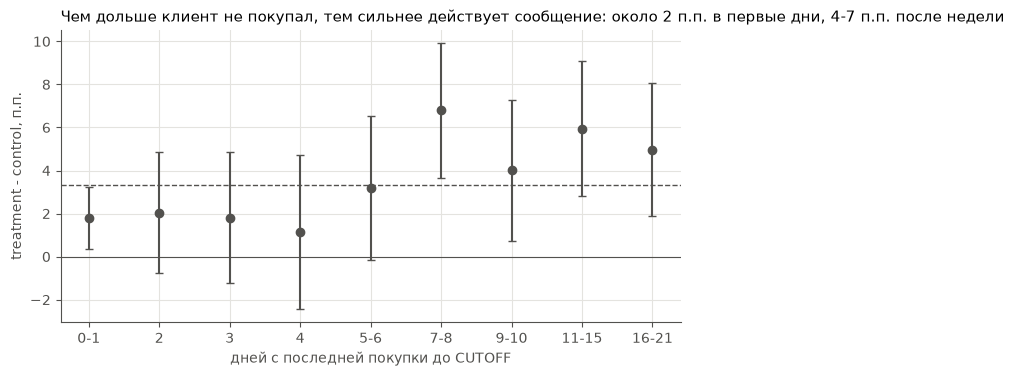

,клиентов,"купили, treatment","купили, control",uplift_pp,lo_pp,hi_pp
bin,,,,,,
"(-0.001, 1.0]",11478,0.816,0.798,1.797,0.354,3.241
"(1.0, 2.0]",3724,0.756,0.735,2.049,-0.749,4.847
"(2.0, 3.0]",3688,0.678,0.660,1.809,-1.228,4.845
"(3.0, 4.0]",2740,0.649,0.638,1.145,-2.443,4.733
"(4.0, 6.0]",3341,0.599,0.567,3.168,-0.174,6.510
"(6.0, 8.0]",3915,0.548,0.480,6.790,3.665,9.915
"(8.0, 10.0]",3541,0.457,0.416,4.012,0.748,7.277
"(10.0, 15.0]",3878,0.472,0.412,5.951,2.831,9.072
"(15.0, 21.0]",3703,0.380,0.330,4.965,1.887,8.044


In [11]:
bins = pd.qcut(X_valid.days_since_last, 10, duplicates="drop")
df = pd.DataFrame({"bin": bins.to_numpy(), "y": y_v, "t": t_v})
g = df.groupby(["bin", "t"], observed=True).y.agg(["sum", "count"]).unstack("t")
d, lo, hi = stats.diff_props_ci(g[("sum", 1)], g[("count", 1)], g[("sum", 0)], g[("count", 0)])
recency = pd.DataFrame({
    "клиентов": g[("count", 1)] + g[("count", 0)],
    "купили, treatment": g[("sum", 1)] / g[("count", 1)],
    "купили, control": g[("sum", 0)] / g[("count", 0)],
    "uplift": d, "lo": lo, "hi": hi,
})
def bin_label(b, first):
    lo, hi = (0 if first else int(np.floor(b.left)) + 1), int(b.right)
    return str(hi) if lo == hi else f"{lo}-{hi}"


labels = [bin_label(b, i == 0) for i, b in enumerate(recency.index)]

fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(recency))
ax.errorbar(x, recency.uplift * 100, yerr=[(recency.uplift - recency.lo) * 100, (recency.hi - recency.uplift) * 100],
            fmt="o", color=plots.INK, capsize=3)
ax.axhline(y_v[t_v == 1].mean() * 100 - y_v[t_v == 0].mean() * 100, color=plots.INK, ls="--", lw=1)
ax.axhline(0, color=plots.INK, lw=0.8)
ax.set_xticks(x, labels)
ax.set_xlabel("дней с последней покупки до CUTOFF")
ax.set_ylabel("treatment - control, п.п.")
plots.decimal_comma(ax.yaxis)
ax.set_title('Чем дольше клиент не покупал, тем сильнее действует сообщение: около 2 п.п. в первые дни, 4-7 п.п. после недели')
plots.save(fig, "recency_uplift_valid.png")
plt.show()
recency.assign(uplift_pp=lambda d: d.uplift * 100, lo_pp=lambda d: d.lo * 100, hi_pp=lambda d: d.hi * 100)[
    ["клиентов", "купили, treatment", "купили, control", "uplift_pp", "lo_pp", "hi_pp"]].round(3)

Наблюдаемый uplift растёт с давностью последней покупки: +1,8 п.п. (0,4 ... 3,2) у покупавших в последние два дня
истории (0-1 день до CUTOFF), 1-3 п.п. при 2-6 днях и 4-7 п.п. у тех, кто не покупал неделю и больше (+6,8 при 7-8 днях, +5,0 при 16-21).
Это то же, что делает обратный отклик: писать тем, кто реже покупает. Простое правило «не покупал неделю» даёт
около 5 п.п. против 3,3 в среднем, но не 9,6, как верхний дециль модели.

## Итоги

- На test финальная модель (трансформация классов, seed 42) обгоняет случайную рассылку: Qini 0,015
  (0,009 ... 0,022), 112 дополнительных покупателей на 1 000 сообщений в топ-10% против 33.
- Модель отклика хуже случайной рассылки и на valid, и на test: она пишет тем, кто купит и без сообщения.
- Обратный отклик - сильный простой бейзлайн. Модель обгоняет его по uplift@10/20/30, но не по Qini:
  её добавка - в начале списка.
- T-learner и трансформация классов на test не различаются.
- Экономика: рассылка всем окупается при r < ATE = 0,0332, модель - при r от 0 до 0,10 (интервал прибыли выше
  нуля непрерывно; отдельные точки выше 0,10 - шум). С r около ATE модель значимо выгоднее рассылки всем,
  при r от 0,0375 до 0,2175 - и обратного отклика. Цифры прибыли - в единицах V при допущении r = C / V.